In [ ]:
!pip install -q gdown tensorflow scikit-learn pillow requests

In [ ]:
import os
import glob
import requests
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from io import BytesIO

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

warnings.filterwarnings("ignore")

print("All libraries imported successfully.")

All libraries imported successfully.


In [ ]:
# Download Fakeddit dataset

import gdown
import os

print("Downloading Fakeddit dataset...")

gdown.download_folder(
    "https://drive.google.com/drive/folders/1jU7qgDqU1je9Y0PMKJ_f31yXRo5uWGFm",
    output="/content/fakeddit_data",
    quiet=False
)

print("\nDownload completed.")
print("Files downloaded:")

for root, dirs, files in os.walk("/content/fakeddit_data"):
    for file in files:
        print(os.path.join(root, file))

Retrieving folder contents


Retrieving folder 1qYgeupmblRZDsUNaasJEtIJ6Sv-PEOlF all_samples (also includes non multimodal)
Processing file 1gPSV95sL7RU_vEG4-I9sp_rguqrDA8jL all_test_public.tsv
Processing file 1jfTO-aLbR_w2stAkijFOL0dbSE__LeOI all_train.tsv
Processing file 1C5_2_2M_6r7mtQJulrXizjAb95vxRibr all_validate.tsv
Retrieving folder 1DuH0YaEox08ZwzZDpRMOaFpMCeRyxiEF multimodal_only_samples
Processing file 1p9EewIKVcFbipVRLZNGYc2JbSC7A0SWv multimodal_test_public.tsv
Processing file 1XsOkD3yhxgWu8URMes0S9LVSwuFJ4pT6 multimodal_train.tsv
Processing file 1Z99QrwpthioZQY2U6HElmnx8jazf7-Kv multimodal_validate.tsv


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1gPSV95sL7RU_vEG4-I9sp_rguqrDA8jL
To: /content/fakeddit_data/all_samples (also includes non multimodal)/all_test_public.tsv
100%|██████████| 23.9M/23.9M [00:00<00:00, 56.6MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1jfTO-aLbR_w2stAkijFOL0dbSE__LeOI
From (redirected): https://drive.google.com/uc?id=1jfTO-aLbR_w2stAkijFOL0dbSE__LeOI&confirm=t&uuid=526094cb-fe52-4a49-bbb5-33ceaf7f33e9
To: /content/fakeddit_data/all_samples (also includes non multimodal)/all_train.tsv
100%|██████████| 229M/229M [00:02<00:00, 84.1MB/s]
Downloading...
From: https://drive.google.com/uc?id=1C5_2_2M_6r7mtQJulrXizjAb95vxRibr
To: /content/fakeddit_data/all_samples (also includes non multimodal)/all_validate.tsv
100%|██████████| 23.9M/23.9M [00:00<00:00, 35.8MB/s]
Downloading...
From: https://drive.google.com/uc?id=1p9EewIKVcFbipVRLZNG


Download completed.
Files downloaded:
/content/fakeddit_data/multimodal_only_samples/multimodal_train.tsv
/content/fakeddit_data/multimodal_only_samples/multimodal_validate.tsv
/content/fakeddit_data/multimodal_only_samples/multimodal_test_public.tsv
/content/fakeddit_data/all_samples (also includes non multimodal)/all_train.tsv
/content/fakeddit_data/all_samples (also includes non multimodal)/all_validate.tsv
/content/fakeddit_data/all_samples (also includes non multimodal)/all_test_public.tsv



Download completed


In [ ]:
# Load Fakeddit multimodal training dataset

train_path = "/content/fakeddit_data/multimodal_only_samples/multimodal_train.tsv"

df = pd.read_csv(
    train_path,
    sep="\t",
    low_memory=False
)

print("FAKEDDIT MULTIMODAL DATASET")
print("---------------------------")
print("Number of Records:", df.shape[0])
print("Number of Variables:", df.shape[1])

print("\nColumn Names:")
print(list(df.columns))

print("\nFirst 5 Records:")
print(df.head().to_string(index=False))

FAKEDDIT MULTIMODAL DATASET
---------------------------
Number of Records: 564000
Number of Variables: 16

Column Names:
['author', 'clean_title', 'created_utc', 'domain', 'hasImage', 'id', 'image_url', 'linked_submission_id', 'num_comments', 'score', 'subreddit', 'title', 'upvote_ratio', '2_way_label', '3_way_label', '6_way_label']

First 5 Records:
        author                                                                                  clean_title  created_utc        domain  hasImage     id                                                                                                                                                  image_url linked_submission_id  num_comments  score         subreddit                                                                                        title  upvote_ratio  2_way_label  3_way_label  6_way_label
   Alexithymia my walgreens offbrand mucinex was engraved with the letters mucinex but in a different order 1551641244.0   i.imgur.com

In [ ]:
# Select required multimodal columns

text_column = "clean_title"
image_column = "image_url"
label_column = "2_way_label"

data = df[
    [text_column, image_column, label_column]
].copy()

# Remove missing values
data = data.dropna(
    subset=[
        text_column,
        image_column,
        label_column
    ]
)

# Make sure labels are numeric
data[label_column] = pd.to_numeric(
    data[label_column],
    errors="coerce"
)

# Keep only binary labels: 0 and 1
data = data[
    data[label_column].isin([0, 1])
]

# Clean text
data[text_column] = (
    data[text_column]
    .astype(str)
    .str.lower()
    .str.strip()
)

# Keep valid image URLs
data = data[
    data[image_column]
    .astype(str)
    .str.startswith("http")
]

data = data.reset_index(drop=True)

print("SELECTED MULTIMODAL DATA")
print("------------------------")
print("Text Column:", text_column)
print("Image Column:", image_column)
print("Label Column:", label_column)

print("\nRecords after cleaning:", len(data))

print("\nMissing Values:")
print(data.isnull().sum())

print("\nClass Distribution:")
print(data[label_column].value_counts())

print("\nFirst 5 Selected Records:")
print(
    data.head(5).to_string(index=False)
)

SELECTED MULTIMODAL DATA
------------------------
Text Column: clean_title
Image Column: image_url
Label Column: 2_way_label

Records after cleaning: 562466

Missing Values:
clean_title    0
image_url      0
2_way_label    0
dtype: int64

Class Distribution:
2_way_label
0    341460
1    221006
Name: count, dtype: int64

First 5 Selected Records:
                                                                                 clean_title                                                                                                                                                  image_url  2_way_label
my walgreens offbrand mucinex was engraved with the letters mucinex but in a different order https://external-preview.redd.it/WylDbZrnbvZdBpgfa3ntxYf17CBHndiJWHylVm2j_nY.jpg?width=320&crop=smart&auto=webp&s=449659a10792de4d55c2f27d2176fdc8bc66e72a            1
                                                         this concerned sink with a tiny hat                                      

In [ ]:
# Create a balanced and manageable multimodal dataset

SAMPLES_PER_CLASS = 150

class_0 = data[data[label_column] == 0].sample(
    n=SAMPLES_PER_CLASS,
    random_state=42
)

class_1 = data[data[label_column] == 1].sample(
    n=SAMPLES_PER_CLASS,
    random_state=42
)

data_small = pd.concat(
    [class_0, class_1]
).sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("BALANCED FAKEDDIT DATASET")
print("-------------------------")
print("Total Samples:", len(data_small))

print("\nClass Distribution:")
print(data_small[label_column].value_counts())

print("\nFirst 5 Records:")
print(data_small.head().to_string(index=False))

BALANCED FAKEDDIT DATASET
-------------------------
Total Samples: 300

Class Distribution:
2_way_label
1    150
0    150
Name: count, dtype: int64

First 5 Records:
                                                                      clean_title                                                                                                                                                  image_url  2_way_label
                               theres a tree growing on the roof above my bedroom                                        https://preview.redd.it/r2oge0fxntf31.jpg?width=320&crop=smart&auto=webp&s=ca67f38b4e88f6e0a8bf270e2d94bf1cf5674b01            1
                                       this hyena fending off a pack of wild dogs                                        https://preview.redd.it/zi69ekg3h1x21.jpg?width=320&crop=smart&auto=webp&s=6b4882e8665ed7ed656ec615a4bc7493f6e25ffc            1
this prediction of the future of technology in my local newspaper from january th ht

In [ ]:
# Split the balanced dataset into training and testing sets

train_df, test_df = train_test_split(
    data_small,
    test_size=0.20,
    random_state=42,
    stratify=data_small[label_column]
)

print("DATASET SPLIT")
print("-------------")
print("Total Samples:", len(data_small))
print("Training Samples:", len(train_df))
print("Testing Samples:", len(test_df))

print("\nTraining Class Distribution:")
print(train_df[label_column].value_counts())

print("\nTesting Class Distribution:")
print(test_df[label_column].value_counts())

DATASET SPLIT
-------------
Total Samples: 300
Training Samples: 240
Testing Samples: 60

Training Class Distribution:
2_way_label
1    120
0    120
Name: count, dtype: int64

Testing Class Distribution:
2_way_label
0    30
1    30
Name: count, dtype: int64


In [ ]:
# Extract text features using TF-IDF

tfidf = TfidfVectorizer(
    max_features=1000,
    stop_words="english",
    ngram_range=(1, 2)
)

X_text_train = tfidf.fit_transform(
    train_df[text_column]
)

X_text_test = tfidf.transform(
    test_df[text_column]
)

print("TF-IDF TEXT FEATURE EXTRACTION")
print("--------------------------------")
print("Training Text Feature Shape:", X_text_train.shape)
print("Testing Text Feature Shape :", X_text_test.shape)
print("Number of TF-IDF Features:", len(tfidf.get_feature_names_out()))

TF-IDF TEXT FEATURE EXTRACTION
--------------------------------
Training Text Feature Shape: (240, 1000)
Testing Text Feature Shape : (60, 1000)
Number of TF-IDF Features: 1000


In [ ]:
# Load pretrained CNN model for image feature extraction

print("Loading MobileNetV2 CNN model...")

cnn_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    pooling="avg"
)

print("MobileNetV2 loaded successfully.")
print("Image Feature Size:", cnn_model.output_shape[-1])

Loading MobileNetV2 CNN model...
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 loaded successfully.
Image Feature Size: 1280


In [ ]:
# Download and preprocess Fakeddit images

import os
import requests
import numpy as np
from PIL import Image
from io import BytesIO

image_folder = "/content/fakeddit_images"

os.makedirs(image_folder, exist_ok=True)


def download_and_extract_features(df_part, part_name):

    features = []
    valid_indices = []

    print(f"\nProcessing {part_name} images...")

    for count, (idx, row) in enumerate(df_part.iterrows(), start=1):

        try:
            response = requests.get(
                row[image_column],
                headers={"User-Agent": "Mozilla/5.0"},
                timeout=10
            )

            if response.status_code != 200:
                continue

            image = Image.open(
                BytesIO(response.content)
            ).convert("RGB")

            # Resize image for MobileNetV2
            image = image.resize((224, 224))

            # Convert image to NumPy array
            image_array = np.array(
                image,
                dtype=np.float32
            )

            # Add batch dimension
            image_array = np.expand_dims(
                image_array,
                axis=0
            )

            # MobileNetV2 preprocessing
            image_array = preprocess_input(
                image_array
            )

            # Extract CNN features
            feature = cnn_model.predict(
                image_array,
                verbose=0
            )[0]

            features.append(feature)
            valid_indices.append(idx)

        except Exception:
            continue

        if count % 25 == 0:
            print(
                f"Processed {count}/{len(df_part)} images"
            )

    return np.array(features), valid_indices


# Process training images
X_image_train, train_valid_indices = (
    download_and_extract_features(
        train_df,
        "training"
    )
)

# Process testing images
X_image_test, test_valid_indices = (
    download_and_extract_features(
        test_df,
        "testing"
    )
)

print("\nIMAGE FEATURE EXTRACTION COMPLETED")
print("-----------------------------------")
print(
    "Training Image Features:",
    X_image_train.shape
)

print(
    "Testing Image Features:",
    X_image_test.shape
)

print(
    "\nValid Training Images:",
    len(train_valid_indices)
)

print(
    "Valid Testing Images:",
    len(test_valid_indices)
)


Processing training images...
Processed 25/240 images
Processed 50/240 images
Processed 75/240 images
Processed 100/240 images
Processed 125/240 images
Processed 175/240 images
Processed 200/240 images
Processed 225/240 images

Processing testing images...
Processed 25/60 images
Processed 50/60 images

IMAGE FEATURE EXTRACTION COMPLETED
-----------------------------------
Training Image Features: (228, 1280)
Testing Image Features: (58, 1280)

Valid Training Images: 228
Valid Testing Images: 58


In [ ]:
# Align text, image and label data

train_valid_df = train_df.loc[
    train_valid_indices
].copy()

test_valid_df = test_df.loc[
    test_valid_indices
].copy()

# Extract TF-IDF features for only the rows
# where a valid image was obtained
X_text_train_valid = tfidf.transform(
    train_valid_df[text_column]
)

X_text_test_valid = tfidf.transform(
    test_valid_df[text_column]
)

# Target labels
y_train = train_valid_df[label_column].astype(int)
y_test = test_valid_df[label_column].astype(int)

print("ALIGNED MULTIMODAL DATA")
print("-----------------------")
print("Training Samples:", len(y_train))
print("Testing Samples :", len(y_test))

print("\nTraining Text Features:",
      X_text_train_valid.shape)

print("Training Image Features:",
      X_image_train.shape)

print("\nTesting Text Features:",
      X_text_test_valid.shape)

print("Testing Image Features:",
      X_image_test.shape)

print("\nTraining Labels:")
print(y_train.value_counts())

print("\nTesting Labels:")
print(y_test.value_counts())

ALIGNED MULTIMODAL DATA
-----------------------
Training Samples: 228
Testing Samples : 58

Training Text Features: (228, 1000)
Training Image Features: (228, 1280)

Testing Text Features: (58, 1000)
Testing Image Features: (58, 1280)

Training Labels:
2_way_label
0    117
1    111
Name: count, dtype: int64

Testing Labels:
2_way_label
0    29
1    29
Name: count, dtype: int64


In [ ]:
# Combine text and image features

# Convert TF-IDF sparse matrices to dense arrays
X_text_train_dense = X_text_train_valid.toarray()
X_text_test_dense = X_text_test_valid.toarray()

# Scale image features
image_scaler = StandardScaler()

X_image_train_scaled = image_scaler.fit_transform(
    X_image_train
)

X_image_test_scaled = image_scaler.transform(
    X_image_test
)

# Combine text and image features
X_train_combined = np.hstack(
    [
        X_text_train_dense,
        X_image_train_scaled
    ]
)

X_test_combined = np.hstack(
    [
        X_text_test_dense,
        X_image_test_scaled
    ]
)

print("MULTIMODAL FEATURE FUSION")
print("-------------------------")

print(
    "Text Features per Sample:",
    X_text_train_dense.shape[1]
)

print(
    "Image Features per Sample:",
    X_image_train_scaled.shape[1]
)

print(
    "Combined Training Features:",
    X_train_combined.shape
)

print(
    "Combined Testing Features:",
    X_test_combined.shape
)

MULTIMODAL FEATURE FUSION
-------------------------
Text Features per Sample: 1000
Image Features per Sample: 1280
Combined Training Features: (228, 2280)
Combined Testing Features: (58, 2280)


In [ ]:
# Train Logistic Regression classification model

print("TRAINING CLASSIFICATION MODEL")
print("-----------------------------")

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(
    X_train_combined,
    y_train
)

print("Logistic Regression model trained successfully.")
print("Training Samples:", X_train_combined.shape[0])
print("Features Used:", X_train_combined.shape[1])

TRAINING CLASSIFICATION MODEL
-----------------------------
Logistic Regression model trained successfully.
Training Samples: 228
Features Used: 2280


In [ ]:
# Predict the test data and calculate accuracy

print("MULTIMODAL FAKE NEWS PREDICTION")
print("--------------------------------")

y_pred = model.predict(
    X_test_combined
)

accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Actual Test Samples:", len(y_test))
print("Predicted Samples:", len(y_pred))

print("\nAccuracy:",
      round(accuracy * 100, 2),
      "%")

print("\nActual Labels:")
print(y_test.to_numpy())

print("\nPredicted Labels:")
print(y_pred)

MULTIMODAL FAKE NEWS PREDICTION
--------------------------------
Actual Test Samples: 58
Predicted Samples: 58

Accuracy: 51.72 %

Actual Labels:
[0 0 0 0 0 0 1 0 1 0 1 1 0 1 1 1 1 0 1 1 0 0 1 0 1 0 0 1 0 1 0 1 1 0 0 1 0
 1 1 1 0 1 1 1 0 0 1 0 1 0 0 1 0 1 1 0 0 1]

Predicted Labels:
[0 0 0 1 0 0 0 1 0 0 0 1 0 1 1 1 0 1 1 1 0 0 0 0 1 0 0 0 1 0 0 1 0 1 1 1 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0]


CLASSIFICATION REPORT
---------------------
              precision    recall  f1-score   support

     Class 0       0.51      0.72      0.60        29
     Class 1       0.53      0.31      0.39        29

    accuracy                           0.52        58
   macro avg       0.52      0.52      0.50        58
weighted avg       0.52      0.52      0.50        58


CONFUSION MATRIX
----------------
[[21  8]
 [20  9]]


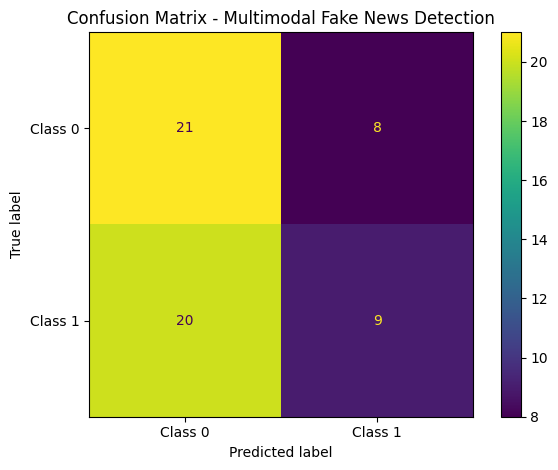

In [ ]:
# Generate classification report and confusion matrix

print("CLASSIFICATION REPORT")
print("---------------------")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Class 0",
            "Class 1"
        ]
    )
)

# Calculate confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred
)

print("\nCONFUSION MATRIX")
print("----------------")
print(cm)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Class 0",
        "Class 1"
    ]
)

disp.plot()

plt.title(
    "Confusion Matrix - Multimodal Fake News Detection"
)

plt.tight_layout()
plt.show()

In [ ]:
# Final results summary

print("==============================================")
print("   ASSIGNMENT 10 - FINAL RESULTS")
print("   MULTIMODAL FAKE NEWS DETECTION")
print("==============================================")

print("\nDataset: Fakeddit")
print("Original Multimodal Records: 564000")
print("Balanced Samples Used: 300")

print("\nFeatures:")
print("Text Features (TF-IDF): 1000")
print("Image Features (MobileNetV2): 1280")
print("Combined Features: 2280")

print("\nMultimodal Samples Successfully Processed:")
print("Training Samples:", len(y_train))
print("Testing Samples :", len(y_test))

print("\nClassification Model:")
print("Logistic Regression")

print("\nFINAL ACCURACY:",
      round(accuracy * 100, 2), "%")

print("\nCONFUSION MATRIX:")
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Class 0", "Class 1"]
    )
)

print("\n==============================================")
print("Assignment 10 completed successfully.")
print("==============================================")

   ASSIGNMENT 10 - FINAL RESULTS
   MULTIMODAL FAKE NEWS DETECTION

Dataset: Fakeddit
Original Multimodal Records: 564000
Balanced Samples Used: 300

Features:
Text Features (TF-IDF): 1000
Image Features (MobileNetV2): 1280
Combined Features: 2280

Multimodal Samples Successfully Processed:
Training Samples: 228
Testing Samples : 58

Classification Model:
Logistic Regression

FINAL ACCURACY: 51.72 %

CONFUSION MATRIX:
[[21  8]
 [20  9]]

Classification Report:
              precision    recall  f1-score   support

     Class 0       0.51      0.72      0.60        29
     Class 1       0.53      0.31      0.39        29

    accuracy                           0.52        58
   macro avg       0.52      0.52      0.50        58
weighted avg       0.52      0.52      0.50        58


Assignment 10 completed successfully.
